# Gradient Boosting — XGBoost and LightGBM

## Titanic Survival Prediction Mini Project

### Topics
- Gradient Boosting basics
- XGBoost
- LightGBM
- Important hyperparameters
- Titanic data preparation
- Model training and prediction
- Accuracy, Precision, Recall, F1-score and ROC-AUC
- Confusion matrix
- Feature importance
- Hyperparameter tuning
- Model comparison
- Practice questions

### Project objective
Predict whether a Titanic passenger survived using `survived` as the target variable.


# 1. Gradient Boosting

Gradient Boosting is an ensemble learning technique that builds models sequentially. Usually, small decision trees are added one after another. Each new tree tries to improve the current ensemble by reducing prediction loss.

**Basic idea:** Model 1 → find errors → Model 2 learns to reduce them → Model 3 improves further → final ensemble.

### Important parameters
- `n_estimators`: number of boosting rounds/trees
- `learning_rate`: contribution of each tree
- `max_depth`: tree complexity
- `subsample`: fraction of rows used in a boosting step
- regularization parameters: help control overfitting

A smaller learning rate often needs more trees, but the best combination is data-dependent.


# 2. XGBoost

XGBoost (Extreme Gradient Boosting) is a gradient-boosted tree implementation with a scikit-learn-style API. Its Python package supports classification, regression and ranking.

### Common parameters
| Parameter | Meaning |
|---|---|
| `n_estimators` | Number of boosting rounds |
| `learning_rate` | Step size/contribution of each tree |
| `max_depth` | Maximum tree depth |
| `subsample` | Fraction of rows used |
| `colsample_bytree` | Fraction of features used |
| `gamma` | Minimum loss reduction for a split |
| `reg_alpha` | L1 regularization |
| `reg_lambda` | L2 regularization |

XGBoost's current documentation describes `learning_rate` as step-size shrinkage and `max_depth` as maximum tree depth. It also supports early stopping with validation data.


# 3. LightGBM

LightGBM is a gradient boosting framework with a Python package and a scikit-learn-style `LGBMClassifier`. It supports pandas DataFrames and validation/early-stopping workflows.

### Common parameters
| Parameter | Meaning |
|---|---|
| `n_estimators` | Number of boosting iterations |
| `learning_rate` | Contribution of each boosting step |
| `num_leaves` | Maximum number of leaves |
| `max_depth` | Maximum tree depth |
| `min_child_samples` | Minimum observations in a leaf |
| `subsample` | Fraction of rows used |
| `colsample_bytree` | Fraction of features used |
| `reg_alpha` | L1 regularization |
| `reg_lambda` | L2 regularization |


# 4. XGBoost vs LightGBM

| Feature | XGBoost | LightGBM |
|---|---|---|
| Basic approach | Gradient-boosted trees | Gradient-boosted trees |
| Classifier | `XGBClassifier` | `LGBMClassifier` |
| Tree control | `max_depth` | `num_leaves`, `max_depth` |
| Learning rate | `learning_rate` | `learning_rate` |
| Number of trees | `n_estimators` | `n_estimators` |
| Regularization | Yes | Yes |
| Early stopping | Supported | Supported |

There is no universal winner; results depend on data, preprocessing and hyperparameters.


# 5. Titanic Mini Project

**Target:** `survived` (1 = survived, 0 = did not survive)

**Features:** `pclass`, `sex`, `age`, `sibsp`, `parch`, `fare`, `embarked`.

Workflow: Load → Explore → Select features → Split → Handle missing values → Encode categories → Train XGBoost → Train LightGBM → Evaluate → Compare → Tune.


In [1]:
# Install once if required
# pip install pandas numpy seaborn scikit-learn xgboost lightgbm matplotlib


In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)
from xgboost import XGBClassifier



In [3]:
from lightgbm import LGBMClassifier

In [4]:
df = sns.load_dataset("titanic")
print(df.head())
print("Shape:", df.shape)
print(df.isnull().sum())


   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  
Shape: (891, 15)
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male  

In [5]:
features = ["pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]
X = df[features]
y = df["survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)




In [6]:
numeric_features = ["pclass", "age", "sibsp", "parch", "fare"]
categorical_features = ["sex", "embarked"]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])


# 6. XGBoost Model

For binary classification, `XGBClassifier` can be used with a binary logistic objective.


In [24]:
xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBClassifier(
        n_estimators=200, learning_rate=0.05, max_depth=4,
        subsample=0.8, colsample_bytree=0.8,
        objective="binary:logistic", eval_metric="logloss",
        random_state=1, n_jobs=-1
    ))
])




In [8]:
xgb_model.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['pclass','sex','age',...,'parch','fare','embarked']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns tha

In [26]:
xgb_model.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['pclass','sex','age',...,'parch','fare','embarked']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns tha

In [27]:
y_pred_xgb = xgb_model.predict(X_test)
y_prob_xgb = xgb_model.predict_proba(X_test)




In [28]:
y_prob_xgb

array([[0.9310755 , 0.06892448],
       [0.8946563 , 0.10534368],
       [0.8667352 , 0.13326477],
       [0.91812754, 0.08187246],
       [0.43631226, 0.56368774],
       [0.6253847 , 0.37461528],
       [0.10636693, 0.89363307],
       [0.33513904, 0.66486096],
       [0.37166613, 0.62833387],
       [0.8500846 , 0.1499154 ],
       [0.80628014, 0.19371988],
       [0.90933436, 0.09066563],
       [0.4797935 , 0.5202065 ],
       [0.7975447 , 0.20245525],
       [0.84519786, 0.15480214],
       [0.83895797, 0.16104203],
       [0.8992389 , 0.10076112],
       [0.9190646 , 0.0809354 ],
       [0.9757098 , 0.02429018],
       [0.05808067, 0.9419193 ],
       [0.9190646 , 0.0809354 ],
       [0.15223545, 0.84776455],
       [0.86519045, 0.13480954],
       [0.67232347, 0.32767656],
       [0.91906744, 0.08093254],
       [0.01595402, 0.984046  ],
       [0.80628014, 0.19371988],
       [0.77646273, 0.22353727],
       [0.9134116 , 0.08658835],
       [0.8712037 , 0.12879628],
       [0.

In [12]:
print("XGBoost")
print("Accuracy:", accuracy_score(y_test, y_pred_xgb))
print("Precision:", precision_score(y_test, y_pred_xgb))
print("Recall:", recall_score(y_test, y_pred_xgb))
print("F1:", f1_score(y_test, y_pred_xgb))

XGBoost
Accuracy: 0.8044692737430168
Precision: 0.7931034482758621
Recall: 0.6666666666666666
F1: 0.7244094488188977


# 7. LightGBM Model

LightGBM provides `LGBMClassifier` for classification.


In [29]:
lgbm_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LGBMClassifier(
        n_estimators=200, learning_rate=0.05, num_leaves=31,
        max_depth=4, random_state=1
    ))
])




In [30]:
lgbm_model.fit(X_train, y_train)
y_pred_lgbm = lgbm_model.predict(X_test)
y_prob_lgbm = lgbm_model.predict_proba(X_test)



In [32]:
print("LightGBM")
print("Accuracy:", accuracy_score(y_test, y_pred_lgbm))
print("Precision:", precision_score(y_test, y_pred_lgbm))
print("Recall:", recall_score(y_test, y_pred_lgbm))
print("F1:", f1_score(y_test, y_pred_lgbm))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_lgbm))

LightGBM
Accuracy: 0.7988826815642458
Precision: 0.7796610169491526
Recall: 0.6666666666666666
F1: 0.71875


ValueError: y should be a 1d array, got an array of shape (179, 2) instead.

# 8. Model Comparison

Use multiple metrics rather than accuracy alone.


In [16]:
results = pd.DataFrame({
    "Model": ["XGBoost", "LightGBM"],
    "Accuracy": [accuracy_score(y_test,y_pred_xgb), accuracy_score(y_test,y_pred_lgbm)],
    "Precision": [precision_score(y_test,y_pred_xgb), precision_score(y_test,y_pred_lgbm)],
    "Recall": [recall_score(y_test,y_pred_xgb), recall_score(y_test,y_pred_lgbm)],
    "F1": [f1_score(y_test,y_pred_xgb), f1_score(y_test,y_pred_lgbm)]
})
print(results.round(4))


      Model  Accuracy  Precision  Recall      F1
0   XGBoost    0.8045     0.7931  0.6667  0.7244
1  LightGBM    0.7989     0.7797  0.6667  0.7188


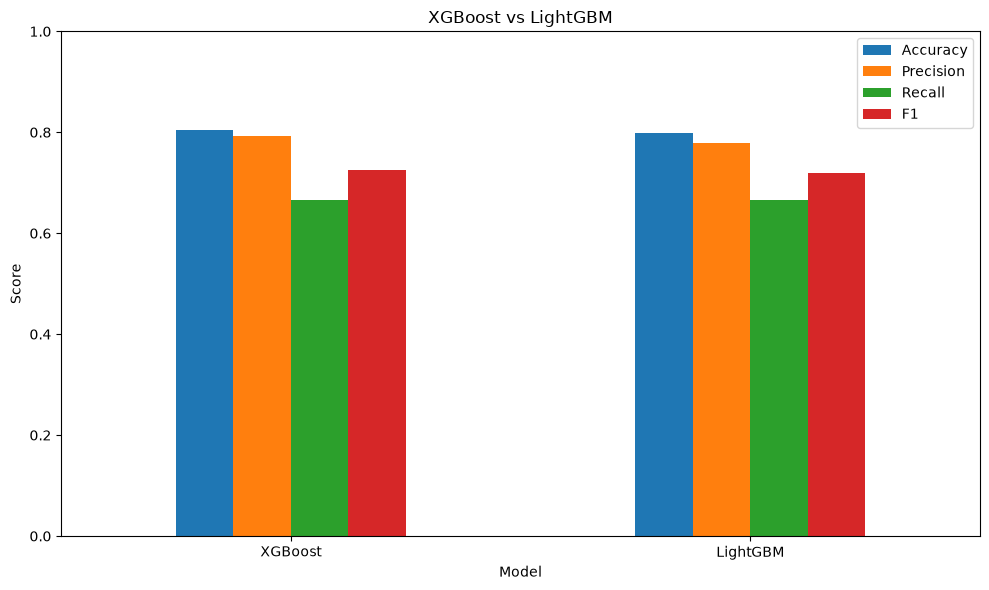

In [17]:
results.set_index("Model").plot(kind="bar", figsize=(10,6))
plt.title("XGBoost vs LightGBM")
plt.ylabel("Score")
plt.ylim(0,1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# 9. Confusion Matrix and Classification Report


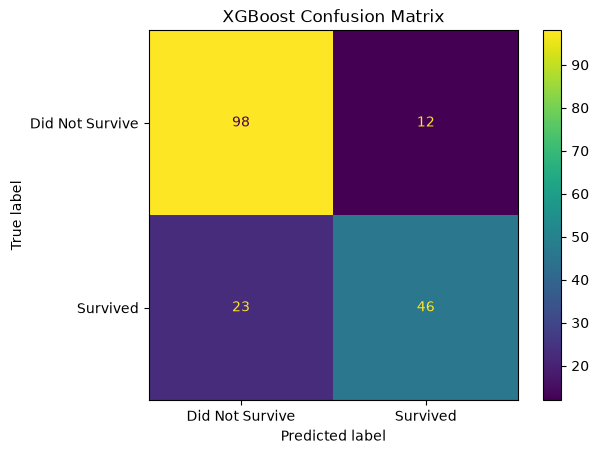

                 precision    recall  f1-score   support

Did Not Survive       0.81      0.89      0.85       110
       Survived       0.79      0.67      0.72        69

       accuracy                           0.80       179
      macro avg       0.80      0.78      0.79       179
   weighted avg       0.80      0.80      0.80       179



In [18]:
cm = confusion_matrix(y_test, y_pred_xgb)
disp = ConfusionMatrixDisplay(cm, display_labels=["Did Not Survive", "Survived"])
disp.plot()
plt.title("XGBoost Confusion Matrix")
plt.show()

print(classification_report(y_test, y_pred_xgb, target_names=["Did Not Survive", "Survived"]))


# 10. Feature Importance

Boosting models can provide feature-importance values. We can inspect the transformed feature names after preprocessing.


           Feature  Importance
6    cat__sex_male    0.431567
5  cat__sex_female    0.255611
0      num__pclass    0.094478
9  cat__embarked_S    0.045893
1         num__age    0.036874
4        num__fare    0.035338
2       num__sibsp    0.033830
3       num__parch    0.023416
7  cat__embarked_C    0.022989
8  cat__embarked_Q    0.020005


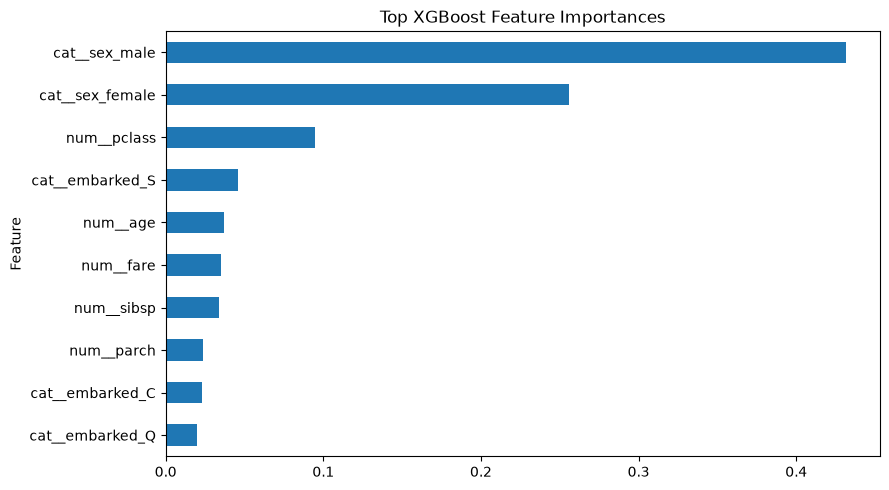

In [19]:
pre = xgb_model.named_steps["preprocessor"]
clf = xgb_model.named_steps["model"]
feature_names = pre.get_feature_names_out()
importance = clf.feature_importances_

importance_df = pd.DataFrame({"Feature": feature_names, "Importance": importance})
importance_df = importance_df.sort_values("Importance", ascending=False)
print(importance_df)

importance_df.head(10).sort_values("Importance").plot(
    x="Feature", y="Importance", kind="barh", figsize=(9,5), legend=False
)
plt.title("Top XGBoost Feature Importances")
plt.tight_layout()
plt.show()


# 11. Hyperparameter Tuning — XGBoost

`GridSearchCV` tests selected combinations using cross-validation. The grid below is deliberately small for a classroom project.


In [20]:
xgb_tune = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBClassifier(
        objective="binary:logistic", eval_metric="logloss",
        random_state=42, n_jobs=-1
    ))
])

param_grid = {
    "model__n_estimators": [100, 200],
    "model__learning_rate": [0.05, 0.10],
    "model__max_depth": [3, 4, 5]
}

grid = GridSearchCV(xgb_tune, param_grid, cv=5, scoring="f1", n_jobs=-1)
grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV F1:", grid.best_score_)


Best parameters: {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 200}
Best CV F1: 0.7478525308307085


In [21]:
best_xgb = grid.best_estimator_
pred = best_xgb.predict(X_test)
prob = best_xgb.predict_proba(X_test)[:,1]
print("Test Accuracy:", accuracy_score(y_test,pred))
print("Test F1:", f1_score(y_test,pred))
print("Test ROC-AUC:", roc_auc_score(y_test,prob))


Test Accuracy: 0.7877094972067039
Test F1: 0.6935483870967742
Test ROC-AUC: 0.8075757575757575


# 12. Hyperparameter Tuning — LightGBM


In [22]:
lgbm_tune = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LGBMClassifier(random_state=42, verbosity=-1))
])

param_grid_lgbm = {
    "model__n_estimators": [100, 200],
    "model__learning_rate": [0.05, 0.10],
    "model__num_leaves": [15, 31]
}

grid_lgbm = GridSearchCV(lgbm_tune, param_grid_lgbm, cv=5, scoring="f1", n_jobs=-1)
grid_lgbm.fit(X_train, y_train)

print("Best parameters:", grid_lgbm.best_params_)
print("Best CV F1:", grid_lgbm.best_score_)


Best parameters: {'model__learning_rate': 0.05, 'model__n_estimators': 200, 'model__num_leaves': 15}
Best CV F1: 0.7608092675554794


In [23]:
best_lgbm = grid_lgbm.best_estimator_
pred = best_lgbm.predict(X_test)
prob = best_lgbm.predict_proba(X_test)[:,1]
print("Test Accuracy:", accuracy_score(y_test,pred))
print("Test F1:", f1_score(y_test,pred))
print("Test ROC-AUC:", roc_auc_score(y_test,prob))


Test Accuracy: 0.7932960893854749
Test F1: 0.7131782945736435
Test ROC-AUC: 0.8004611330698286


# 13. Early Stopping — Concept

Early stopping uses validation performance to stop adding trees when improvement has stopped. XGBoost documents early stopping with validation data; LightGBM provides an early-stopping callback.

The main notebook uses pipelines and GridSearchCV for simplicity. Early stopping is introduced conceptually because its exact implementation depends on how transformed training and validation data are supplied.


# 14. Quick Revision

### Gradient Boosting
Sequentially builds weak learners, usually trees, to reduce loss.

### XGBoost
Important parameters: `n_estimators`, `learning_rate`, `max_depth`, `subsample`, regularization.

### LightGBM
Important parameters: `n_estimators`, `learning_rate`, `num_leaves`, `max_depth`.

### Key reminder
A smaller learning rate often needs more trees. Too much model complexity can overfit. Always evaluate on unseen data.


# 15. Practice Questions

1. What is Gradient Boosting?
2. Why are boosting trees built sequentially?
3. What does `learning_rate` control?
4. What does `n_estimators` mean?
5. What does `max_depth` control?
6. What is `num_leaves` in LightGBM?
7. What is overfitting in boosting?
8. Why might a smaller learning rate require more trees?
9. What is the difference between XGBoost and LightGBM?
10. What is early stopping?
11. Why do we use cross-validation during hyperparameter tuning?
12. Why should the test set not be used for tuning?
13. What does ROC-AUC measure?
14. What is feature importance?
15. Why do tree-based boosting models generally not need StandardScaler?
16. Explain `subsample`.
17. What is regularization?
18. Why compare multiple evaluation metrics?
19. Build an XGBoost Titanic model.
20. Build a LightGBM Titanic model and compare the two.
